# 18. Один кадр, два способа его посчитать

[План курса](../../README_ru.md)

На белом поле лежат пять цветных пятен. В левом верхнем углу почти бело, но простой рендерер из урока 14 всё равно вычисляет вес каждого из пяти пятен для каждого пикселя. Отодвинем камеру в сторону. Пустая часть кадра тоже переедет. Значит, экономию придётся искать заново для каждой камеры.


In [1]:
%matplotlib inline
from pathlib import Path
import sys
for folder in (Path.cwd(), *Path.cwd().parents):
    if (folder / "reconstruction.py").is_file():
        sys.path.insert(0, str(folder))
        break
import json
import numpy as np
import matplotlib.pyplot as plt
from reconstruction import *
from reconstruction_demos import photo_capture, tiles_figure, rays_figure, view_figure, error_figure, controls, damage
lang = 'ru'


## 1. Что лежит в одной клетке

Разрежем кадр на квадраты. Каждый такой квадрат называется *тайлом*. На карте списков светлые клетки почти пусты, тёмные (на сайте насыщенно-синие) пересекают больше пятен. У края экрана клетка может оказаться неполной. При смене стороны тайла меняется количество проверок, а цвет пикселя остаётся тем же. При уменьшении границы пятна меняется уже сама картинка.


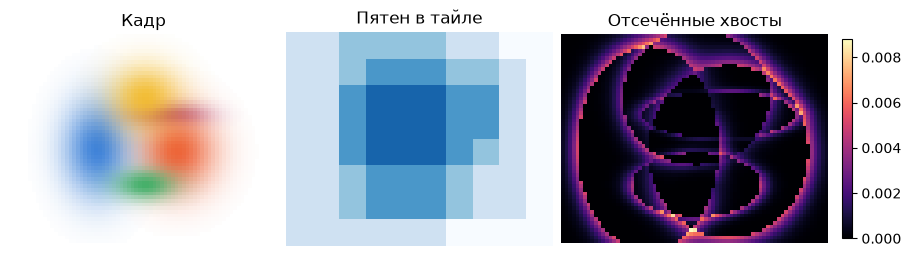

In [2]:
display(tiles_figure(lang=lang))
plt.close()
controls(lambda tile, k, angle: tiles_figure(int(tile), k, angle, lang),
         tile=[8, 4, 16, 32], k=(1., 4., .1, 3.), angle=(-45, 45, 1, 0))


## 2. Где заканчивается мягкое пятно

Строго говоря, нигде. У одномерного колокола с центром 9 и шириной 2 точка 13 находится на $(13-9)/2=2$ ширины правее центра. Возводим 2 в квадрат, получаем 4, делим на −2 и берём экспоненту. Вес равен $e^{-2}\approx0.1353$. На трёх ширинах он ещё положителен, $e^{-9/2}\approx0.0111$. При непрозрачности 0.8 вклад в альфу на этой границе равен $0.8\cdot0.0111\approx0.0089$.

У эллипса вместо одного расстояния два. Пусть центр пиксельного следа $m=(9,6)$, ширины по осям 2 и 1 пиксель. В пикселе $p=(12,7)$ смещения составляют $3$ и $1$ пиксель. Расстояние в единицах собственных ширин, уже возведённое в квадрат,

$$
q=(3/2)^2+(1/1)^2=2.25+1=3.25.
$$

При границе $k=2$ условие $q\le k^2=4$ выполняется. Вес равен $e^{-3.25/2}\approx0.197$. При повороте эллипса из урока 13 тот же расчёт принимает вид $q=(p-m)^T S^{-1}(p-m)$, где $S$ — ковариация следа в квадратных пикселях. Обратная матрица убирает масштаб, поэтому $q$ и $k$ безразмерны. Операция отсечения в обоих вариантах одна: за границей вес равен нулю.


In [3]:
q = (3/2)**2 + (1/1)**2
print("q =", q, "weight =", np.exp(-q/2))
assert q < 2**2 and np.exp(-9/2) < .012


q = 3.25 weight = 0.19691167520419406


## 3. От эллипса к списку тайла

Для того же пятна граница в две ширины доходит по горизонтали от $9-2\cdot2=5$ до $9+2\cdot2=13$, по вертикали от $6-2\cdot1=4$ до 8. Это прямоугольник, обнимающий эллипс. Угловой пиксель может лежать в прямоугольнике, а проверку $q\le4$ не пройти.

Если сторона тайла 4 пикселя, столбцы 0–3 принадлежат тайлу 0, 4–7 — тайлу 1. Номер равен целой части деления координаты на 4. По горизонтали наше пятно касается тайлов 1, 2, 3, по вертикали 1, 2. Получается $3\cdot2=6$ ссылок на одну гауссиану. Сами параметры цвета и формы сохраняются один раз. Для повёрнутой ковариации полуразмер прямоугольника по горизонтали равен $k\sqrt{S_{xx}}$, по вертикали $k\sqrt{S_{yy}}$. Диагонали содержат дисперсию вдоль **экранных** осей; корень возвращает пиксели.

Тест глубины убирает центр позади ближней плоскости. На самом экране одного центра мало для отбрасывания: при горизонтальной координате центра −1 и радиусе 3 пикселя след дотягивается до столбца 2. Пиксель 0 может получить цвет, хотя центр за левой границей. Поэтому со стороной кадра сравнивается прямоугольник следа.

Дальше у каждого пикселя только один список. Сначала идёт ближайший центр, затем следующий по глубине. Новое пятно получает долю $T\alpha$, где $T$ — ещё прозрачная часть луча. При $T=0.6$ и $\alpha=0.25$ цвет этого пятна входит с весом $0.15$, дальше проходит $0.6(1-0.25)=0.45$. Порядок меняет цвет, поэтому в каждом тайле сохраняется одна и та же сортировка.


In [4]:
sc = small_scene()
cam = orbit(0, 73, 57)
slow, brute = finite_render(sc, cam, 73, 57, 8, 3, tiled=False)
fast, bins = finite_render(sc, cam, 73, 57, 8, 3, tiled=True)
print("pairs:", brute["pairs"], "→", bins["pairs"])
print("max |fast − slow|:", np.max(np.abs(fast-slow)))
assert np.allclose(fast, slow, atol=1e-12, rtol=0)


pairs: 20805 → 8688
max |fast − slow|: 0.0


## 4. Счётчик работы и часы

Кадр из 73 × 57 пикселей и пяти видимых пятен даёт 20 805 пар «пиксель, пятно» при полном переборе. Граница обнуляет часть весов, но саму проверку расстояния мы уже оплатили. Списки при стороне 8 оставляют 8 688 таких пар. В тайле из 64 пикселей один лишний кандидат стоит 64 проверки. Мелкие тайлы экономят проверки, крупные экономят ссылки и подготовку. Накладные расходы Python и размер массивов влияют на время отдельно. Для замера сначала рисуется пробный кадр, потом берётся медиана нескольких замеров настенных часов на этой машине.


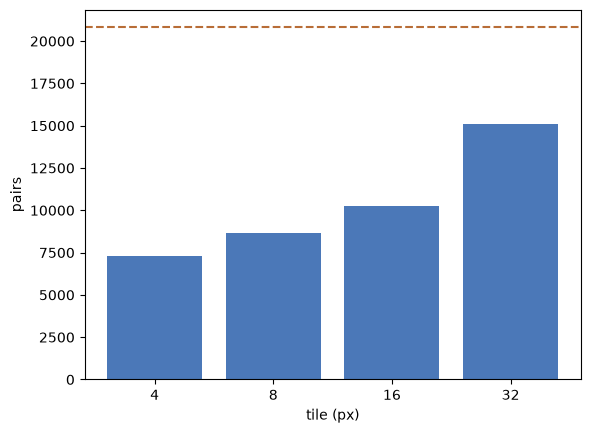

CPU ms: 7.73


In [5]:
sides = [4, 8, 16, 32]
counts = [finite_render(sc, cam, 73, 57, side)[1]["pairs"] for side in sides]
plt.bar([str(s) for s in sides], counts, color="#4b78b8")
plt.axhline(brute["pairs"], color="#b86d37", linestyle="--")
plt.ylabel("pairs"); plt.xlabel("tile (px)"); plt.show()
print("CPU ms:", round(benchmark(lambda: finite_render(sc, cam, 73, 57)), 2))


## 5. Где здесь оригинальная статья

У Kerbl, Kopanas, Leimkühler и Drettakis есть три связанные части. Обучаемые трёхмерные гауссианы хранят форму и цвет, изменение плотности добавляет или убирает элементы, а растеризатор быстро превращает текущую сцену в кадр. Уже знакомая нам ошибка изображения проходит через этот рендерер обратно в параметры. В учебном коде обход списков виден строка за строкой.

Реализация авторов сначала отсеивает невидимые центры, проецирует форму и вычисляет экранный радиус. Для каждой пары «пятно, тайл» появляется запись с номером тайла и глубиной. После сортировки соседние записи одного тайла образуют диапазон. Блок потоков GPU обрабатывает участок экрана, подгружая кандидатов порциями в общую память. Потоки считают свои пиксели одновременно. Там также есть экранная фильтрация, порог очень малой альфы, ограничение альфы сверху и ранняя остановка при малой прозрачности. Поэтому равенство двух наших массивов проверяет именно учебный алгоритм с **одним** порогом. Число миллисекунд выше относится к CPU и этому размеру кадра.

[Статья и результаты](https://repo-sam.inria.fr/fungraph/3d-gaussian-splatting/) · [Подготовка и сортировка тайлов](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/rasterizer_impl.cu) · [Обработка пикселей на GPU](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu)

## Опыт

Что произойдёт с картинкой при переходе от тайла 4 к тайлу 32 и той же границе? А если оставить тайл 4, но срезать пятно уже на одной ширине?

<details><summary>Разбор</summary>

В первом случае поменяются длины списков и число проверок. Веса пикселей и итоговый цвет совпадут. Во втором пропадут даже участки, где вес был около 0.6. Светлые промежутки расширятся. Разность с полным колоколом объясняется сменой поддержки, а не сортировкой.

</details>
